# EN.605.631 — Limit Theorems with R (Chapter 8) — Notebook Shell

**Format:** Jupyter Notebook (**R kernel**)

**Estimated time:** ~5 hours

**Total points:** 100

This shell provides **function stubs** and **plotting scaffolds**. Replace `TODO` with your code.

## Environment & Setup

In [1]:
R.version.string
sessionInfo()
set.seed(631)

# Optional packages
# suppressPackageStartupMessages({
#   library(ggplot2)
#   library(dplyr)
# })

[1] "R version 4.6.1 (2026-06-24 ucrt)"

R version 4.6.1 (2026-06-24 ucrt)
Platform: x86_64-w64-mingw32/x64
Running under: Windows 11 x64 (build 26200)

Matrix products: default
  LAPACK version 3.12.1

locale:
[1] LC_COLLATE=English_United States.utf8 
[2] LC_CTYPE=English_United States.utf8   
[3] LC_MONETARY=English_United States.utf8
[4] LC_NUMERIC=C                          
[5] LC_TIME=English_United States.utf8    

time zone: America/New_York
tzcode source: internal

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

loaded via a namespace (and not attached):
 [1] digest_0.6.39     IRdisplay_1.1     base64enc_0.1-6   fastmap_1.2.0    
 [5] glue_1.8.1        htmltools_0.5.9   repr_1.1.7        lifecycle_1.0.5  
 [9] cli_3.6.6         vctrs_0.7.3       textshaping_1.0.5 pbdZMQ_0.3-14    
[13] systemfonts_1.3.2 compiler_4.6.1    tools_4.6.1       ragg_1.5.2       
[17] evaluate_1.0.5    pillar_1.11.1     rlang_1.3.0       jsonlite_2.0.0   
[21] crayon_1.5.3      IRkernel_1.

## Helper Utilities

In [2]:
mc_se_mean <- function(x) sd(x)/sqrt(length(x))
ci95_prop <- function(p_hat, n){
  se <- sqrt(p_hat*(1-p_hat)/n)
  c(lower = max(0, p_hat - 1.96*se),
    upper = min(1, p_hat + 1.96*se))
}

---
## Problem 1 — Markov, Chebyshev, One-Sided Chebyshev (10 pts)
(a) Prove inequalities. (b) Bounds with μ=50, σ²=400 at a=70. (c) Heavy-tail comparison across a∈{60,70,80,90}.

## a1) Markov inequality

Let $X \ge 0$ and $a > 0$ and let random variable $Z = \{ a$ if $X \ge a$, $0$ if $X < a \}$

There are 2 cases:

+ $X \ge a = Z$
+ $X \ge 0 = Z$ because $X$ is nonnegative

So $X \ge Z$ in all cases

$E[X] \ge E[Z] = a \cdot P(X \ge a) + 0 \cdot P(X < a) = a\,P(X \ge a)$

$P(X \ge a) \le \frac{E[X]}{a}$



## a2) Chebyshev

Let $X$ have mean $\mu$ and variance $\sigma^2$ and let $k > 0$

$(X-\mu)^2$ is nonnegative so Markov applies with threshold $k^2$

$P(|X-\mu| \ge k) = P((X-\mu)^2 \ge k^2) \le \frac{E[(X-\mu)^2]}{k^2} = \frac{\sigma^2}{k^2}$

For one-sided bounds, fix $k > 0$ and any $t \ge 0$

If $X - \mu \ge k$, then $X - \mu + t \ge k + t > 0$

$(X-\mu+t)^2 \ge (k+t)^2$

$P(X-\mu \ge k) \le P((X-\mu+t)^2 \ge (k+t)^2)$

Using Markov gives $P(X-\mu \ge k) \le \frac{E[(X-\mu+t)^2]}{(k+t)^2} = \frac{\sigma^2 + t^2}{(k+t)^2}$ for $E[X-\mu]=0$

Minimize over $t$ for $t = \sigma^2/k$

$P(X-\mu \ge k) \le \frac{\sigma^2}{\sigma^2 + k^2}$.

## b) Upper bounds

For $\mu = 50$, $\sigma^2 = 400$

Markov: $P(X \ge 70) \leq \frac{50}{70} \approx 0.714$

$k = 70 - 50 = 20$

One-sided Chebyshev: $P(X \ge 70)= \frac{400}{400 + 20^2} = 0.5$

One-sided Chebyshev is the tighter bound because Markov only uses the mean (and $X \ge 0$) and one-sided Chebyshev uses the mean and variance

In [3]:
mu <- 50; sig2 <- 400
markov_bounds <- mu / c(60,70,80,90)
cantelli <- sig2 / (sig2 + (c(60,70,80,90)-mu)^2)
s02 <- log(1 + sig2/mu^2); m0 <- log(mu) - s02/2
set.seed(631); N <- 2e5
X <- rlnorm(N, meanlog=m0, sdlog=sqrt(s02))
tail_emp <- sapply(c(60,70,80,90), function(a) mean(X>=a))
data.frame(a=c(60,70,80,90), empirical=tail_emp, Markov=markov_bounds, Cantelli=cantelli)

a,empirical,Markov,Cantelli
<dbl>,<dbl>,<dbl>,<dbl>
60,0.252195,0.8333333,0.8000000
70,0.142685,0.7142857,0.5000000
80,0.078675,0.6250000,0.3076923
90,0.042520,0.5555556,0.2000000


In [4]:
mean(X)
var(X)

[1] 50.00175

[1] 399.013

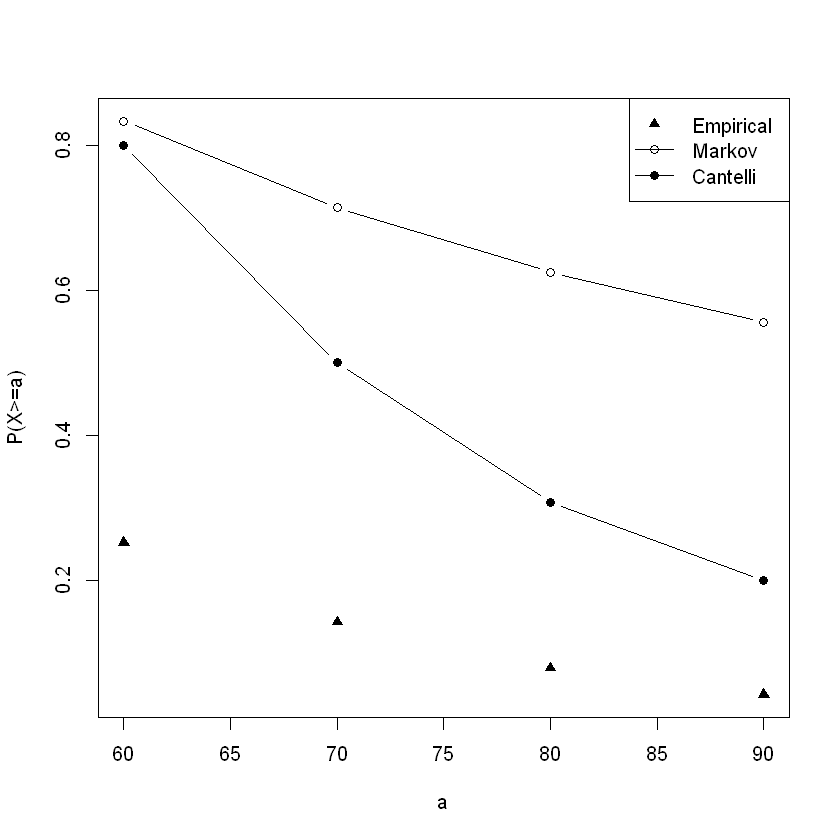

In [5]:
# Plot scaffold
agrid <- c(60,70,80,90)
plot(agrid, markov_bounds, type='b', ylim=range(c(tail_emp, markov_bounds, cantelli)),
     xlab='a', ylab='P(X>=a)')
lines(agrid, cantelli, type='b', pch=19)
points(agrid, tail_emp, pch=17)
legend('topright', legend=c('Empirical','Markov','Cantelli'), pch=c(17,1,19), lty=c(NA,1,1))

---
## Problem 2 — WLLN by Chebyshev (10 pts)
Exp(1). For n∈{25,100,400,1600} and ε∈{0.25,0.1}, estimate P(|x̄−1|>ε); compare to Chebyshev 1/(n ε²).

## a)

Let $X_1, X_2, \dots$ be IID with $E[X_i] = \mu$ and $\mathrm{Var}(X_i) = \sigma^2 < \infty$

Let $\bar X_n = \frac{1}{n}\sum_{i=1}^n X_i$

By linearity, $E[\bar X_n] = \mu$

By independence, $\mathrm{Var}(\bar X_n) = \frac{1}{n^2}\sum_{i=1}^n \mathrm{Var}(X_i) = \frac{\sigma^2}{n}$

Chebyshev's inequality for $\bar X_n$ gives $P(|\bar X_n - \mu| > \varepsilon) \le \frac{\mathrm{Var}(\bar X_n)}{\varepsilon^2}$ for fixed $\varepsilon > 0$

$P(|\bar X_n - \mu| > \varepsilon) \le \frac{\sigma^2}{n\varepsilon^2}$

Since $\sigma^2$ and $\varepsilon$ are fixed, $\lim_{n \to \infty} \frac{\sigma^2}{n\varepsilon^2} = 0$

Probabilities are nonnegative, so $0 \le P(|\bar X_n - \mu| > \varepsilon) \le \frac{\sigma^2}{n\varepsilon^2}$ for every $n$

By the squeeze theorem, $0 \le \lim_{n \to \infty} P(|\bar X_n - \mu| > \varepsilon) \le \lim_{n \to \infty} \frac{\sigma^2}{n\varepsilon^2} = 0$

Therefore $\lim_{n \to \infty} P(|\bar X_n - \mu| > \varepsilon) = 0$ for every $\varepsilon > 0$, which means $\bar X_n \to_p \mu$

## b)

In [6]:
eps <- c(0.25,0.1); ns <- c(25,100,400,1600); reps <- 2e4
est <- array(NA, dim=c(length(ns),length(eps)), dimnames=list(n=ns, eps=eps))
set.seed(631)
for(i in seq_along(ns)){
  n <- ns[i]; X <- matrix(rexp(reps*n), nrow=reps)
  xb <- rowMeans(X)
  for(j in seq_along(eps)) est[i,j] <- mean(abs(xb-1) > eps[j])
}
cheb <- outer(ns, eps, function(n,e) 1/(n*e^2))
list(empirical=est, chebyshev=cheb)

$empirical
      eps
n         0.25    0.1
  25   0.20795 0.6197
  100  0.01240 0.3128
  400  0.00000 0.0448
  1600 0.00000 0.0001

$chebyshev
     [,1]   [,2]
[1,] 0.64 4.0000
[2,] 0.16 1.0000
[3,] 0.04 0.2500
[4,] 0.01 0.0625

The empirical probabilities are always below the bounds and the gap decreases as $n$ increases.

The Chebyshev bound shrinks like $1/n$ because it uses only the variance but the true tail probability of $\bar X_n$ shrinks faster -- roughly exponentially in $n\varepsilon^2$

At $n=1600$ and $\varepsilon = 0.25$ the empirical estimate is essentially $0$ while the bound is $0.01$

---
## Problem 3 — CLT (accuracy & continuity) (14 pts)
Bernoulli(0.3). Approximate P(280≤S₁₀₀₀≤330) with/without cc; validate by MC. Repeat for n=100.

## a)

$S_n = \sum_{i=1}^n X_i$ with $X_i \sim \mathrm{Bernoulli}(0.3)$

$E[S_n] = np$ and $\mathrm{Var}(S_n) = np(1-p)$

For $n=1000$:

$\mu = np = 1000(0.3) = 300$

$\sigma = \sqrt{np(1-p)} = \sqrt{1000(0.3)(1-0.3)} = \sqrt{210} \approx 14.491$

$P(280 \le S_{1000} \le 330) \approx \Phi\left(\frac{330-300}{\sqrt{210}}\right) - \Phi\left(\frac{280-300}{\sqrt{210}}\right) = \Phi(2.070) - \Phi(-1.380)$

With continuity correction, $S_n$ is integer-valued, so $\{280 \le S_n \le 330\} = \{279.5 < S_n < 330.5\}$:

$P(280 \le S_{1000} \le 330) \approx \Phi\left(\frac{330.5-300}{\sqrt{210}}\right) - \Phi\left(\frac{279.5-300}{\sqrt{210}}\right) = \Phi(2.105) - \Phi(-1.415)$

In [7]:
p <- 0.3
approx_clt <- function(n,a,b,continuity=FALSE){
  mu <- n*p; sd <- sqrt(n*p*(1-p))
  lo <- (a-mu)/sd; hi <- (b-mu)/sd
  if(continuity){ lo <- ((a-0.5)-mu)/sd; hi <- ((b+0.5)-mu)/sd }
  pnorm(hi) - pnorm(lo)
}
p1000_nc <- approx_clt(1000,280,330,FALSE)
p1000_cc <- approx_clt(1000,280,330,TRUE)
p1000_nc
p1000_cc

[1] 0.8970099

[1] 0.9037534

## b)

In [8]:
set.seed(631); N <- 1e5; S <- rbinom(N,1000,p)
p_emp <- mean(S>=280 & S<=330); ci <- ci95_prop(p_emp,N)
p_emp
ci
mc_se_mean(S>=280 & S<=330)
abs(p_emp-p1000_nc)
abs(p_emp-p1000_cc)

[1] 0.90392

lower     upper 
0.9020934 0.9057466

[1] 0.0009319308

[1] 0.006910104

[1] 0.0001665763

## c)

In [9]:
set.seed(631)
p100_nc <- approx_clt(100,28,33,FALSE); p100_cc <- approx_clt(100,28,33,TRUE)
S2 <- rbinom(N,100,p); p_emp2 <- mean(S2>=28 & S2<=33); ci2 <- ci95_prop(p_emp2,N)
p100_nc
p100_cc
p_emp2
ci2
mc_se_mean(S2>=28 & S2<=33)
abs(p_emp2-p100_nc)
abs(p_emp2-p100_cc)

[1] 0.4123943

[1] 0.4848062

[1] 0.48198

lower    upper 
0.478883 0.485077

[1] 0.00158012

[1] 0.06958567

[1] 0.002826176

At $n=1000$ the CLT values are close ($0.897$ vs. $0.904$ with correction) but at $n=100$ they differ by a lot ($0.412$ vs $0.485$ with correction),  and the absolute error without the correction at $n=100$ is large compared to the MC SE of about $0.0016$. The error shrinks as $n$ grows, which makes sense by the CLT.

Skewness of $S_n$ is $\frac{1-2p}{\sqrt{np(1-p)}}$. For $p = 0.3$ and $n=1000$ the skewness is $\frac{1-2(0.3)}{\sqrt{1000(0.3)(1-0.3)}}=\frac{0.4}{\sqrt{210}} \approx 0.028$. For $p = 0.3$ and $n=100$ skewness is $\frac{1-2(0.3)}{\sqrt{100(0.3)(1-0.3)}}=\frac{0.4}{\sqrt{21}} \approx 0.087$. The normal is symmetric so skewness cannot be fully fixed by continuity correction. Skewness shrinks like $1/\sqrt{n}$ so the approximation improves as $n$ increases.

---
## Problem 4 — Choose n: CLT vs Chebyshev (12 pts)
σ=4, |x̄−μ|≤0.5 with prob≥0.95. Find n via CLT and Chebyshev. Confirm coverage at CLT n.

## a)

By the CLT, $\bar X_n \approx N(\mu, \frac{\sigma^2}{n})$

$P(|\bar X_n - \mu| \le \varepsilon) \approx P\left(|Z| \le \frac{\varepsilon\sqrt{n}}{\sigma}\right)$ where $Z \sim N(0,1)$

We need this to be at least $1-\alpha = 0.95$. The two-sided condition is

$\frac{\varepsilon\sqrt{n}}{\sigma} \ge z_{1-\alpha/2} = z_{0.975} \approx 1.96$

$n \ge \left(\frac{z_{1-\alpha/2}\,\sigma}{\varepsilon}\right)^2 = \left(\frac{1.96 (4)}{0.5}\right)^2 \approx 245.9$

$n = 246$

In [10]:
sigma <- 4; eps <- 0.5; alpha <- 0.05
n_clt <- ceiling((qnorm(1-alpha/2)*sigma/eps)^2)
n_clt

[1] 246

## b)

$E[\bar X_n] = \mu$ and $\mathrm{Var}(\bar X_n) = \frac{\sigma^2}{n}$

By Chebyshev, $P(|\bar X_n - \mu| > \varepsilon) \le \frac{\sigma^2}{n\varepsilon^2}$

We need the right side to be at most $\alpha = 0.05$

$\frac{\sigma^2}{n\varepsilon^2} \le \alpha$

$n \ge \frac{\sigma^2}{\alpha\varepsilon^2} = \frac{16}{0.05 \cdot 0.5^2} = 1280$

$n = 1280$

In [11]:
n_cheb <- ceiling((sigma/eps)^2 * (1/alpha))
n_cheb

[1] 1280

## c)

Chebyshev needs over 5 times as many observations as CLT because it uses only $\sigma^2$. The bound has to hold for every distribution with that variance so it plans for the worst case. However the CLT answer is smaller but approximate while Chebyshev answer is guaranteed.

In [12]:
set.seed(631); reps <- 1e5
Xbar <- rowMeans(matrix(rnorm(reps*n_clt, sd=sigma), nrow=reps))
cover <- mean(abs(Xbar) <= eps)
c(n_clt=n_clt, n_cheb=n_cheb, empirical_coverage=cover)

n_clt             n_cheb empirical_coverage 
         246.00000         1280.00000            0.95067

---
## Problem 5 — Chernoff vs Chebyshev/Exact (12 pts)
Gaussian tail: exact vs Chernoff e^{-a²/2} vs Chebyshev 1/a². Poisson(10): P(X≥16) bound vs normal(cc) vs exact.

## a)

For any $t > 0$, $x \mapsto e^{tx}$ is increasing, so $Z \ge a$ iif $e^{tZ} \ge e^{ta}$

Apply Morkov to $e^{tZ}$

$P(Z \ge a) = P(e^{tZ} \ge e^{ta}) \le \frac{E[e^{tZ}]}{e^{ta}} = e^{-ta} M_Z(t)$

For $Z \sim N(0,1)$ the MGF is $M_Z(t) = e^{t^2/2}$

$P(Z \ge a) \le \exp\left(\frac{t^2}{2} - ta\right)$ for $t > 0$

$g(t) = \frac{t^2}{2} - ta$

$g'(t) = t - a$

$g''(t) = 1 > 0$

The bound is minimized at $t = a$ with $g(a) = -\frac{a^2}{2}$

This $t$ is valid for $a > 0$

$P(Z \ge a) \le e^{-a^2/2}$

## b)

In [13]:
a <- c(1,1.5,2,2.5,3)
exact <- 1 - pnorm(a); chernoff <- exp(-a^2/2); cheb <- 1/a^2
data.frame(a, exact, chernoff, cheb)

a,exact,chernoff,cheb
<dbl>,<dbl>,<dbl>,<dbl>
1.0,0.158655254,0.60653066,1.0000000
1.5,0.066807201,0.32465247,0.4444444
2.0,0.022750132,0.13533528,0.2500000
2.5,0.006209665,0.04393693,0.1600000
3.0,0.001349898,0.01110900,0.1111111


Chernoff is a better approximation than Chebyshev for all $a > 0$. The gap widens quickly because Chernoff decays exponentially in $a^2$ and Chebyshev decays polynomially.

## c)

For $X \sim \mathrm{Poisson}(\lambda)$ the MGF is $M_X(t) = \exp\left(\lambda(e^t - 1)\right)$, so for $t > 0$

$P(X \ge k) \le \exp\left(-tk + \lambda(e^t - 1)\right)$

Let $g(t) = -tk + \lambda(e^t - 1)$

$g'(t) = -k + \lambda e^t$

Set $g'(t) = 0$:

$\lambda e^t = k$

$e^t = \frac{k}{\lambda}$

$t^* = \ln\left(\frac{k}{\lambda}\right)$

Since $g''(t) = \lambda e^t > 0$, this is a minimum

$P(X \ge k) \le e^{-\lambda}\left(\frac{e\lambda}{k}\right)^k$

For the normal approximation, $X$ is integer-valued, so $\{X \ge 16\} = \{X > 15.5\}$. With $\mu = 10$ and $\sigma = \sqrt{10}$,

$P(X \ge 16) \approx 1 - \Phi\left(\frac{15.5 - 10}{\sqrt{10}}\right) = 1 - \Phi(1.739)$

The exact tail is $P(X \ge 16) = 1 - P(X \le 15)$.

In [14]:
set.seed(631)
lam <- 10; k <- 16; tgrid <- seq(0,2,length=4001)
ch <- min(exp(-tgrid*k + lam*(exp(tgrid)-1)))
mu <- lam; sd <- sqrt(lam)
p_norm <- 1 - pnorm((k-0.5 - mu)/sd)
p_exact <- 1 - ppois(k-1, lam)
c(chernoff=ch, normal_cc=p_norm, exact=p_exact)

chernoff  normal_cc      exact 
0.21869919 0.04099516 0.04874040

The normal approximation with continuity correction gives about $0.041$, which is close but underestimates because the Poisson is right-skewed. The Chernoff bound gives about $0.219$ which is much looser. The normal approximation is more accurate but it has no guarantee and can be off in either direction while Chernoff is valid and always above the truth but not as accurate.

---
## Problem 6 — SLLN Visualization (10 pts)
Uniform(0,1) vs Pareto(α≈2.1) thinned running means up to 10^6.

## a)

$X_i \sim \mathrm{Uniform}(0,1)$

$\mu = \frac{1}{2}$ and $\sigma^2 = \frac{1}{12}$

By SLLN, if $E|X_1| < \infty$, then $P\left(\lim_{n \to \infty} \bar X_n = \mu\right) = 1$

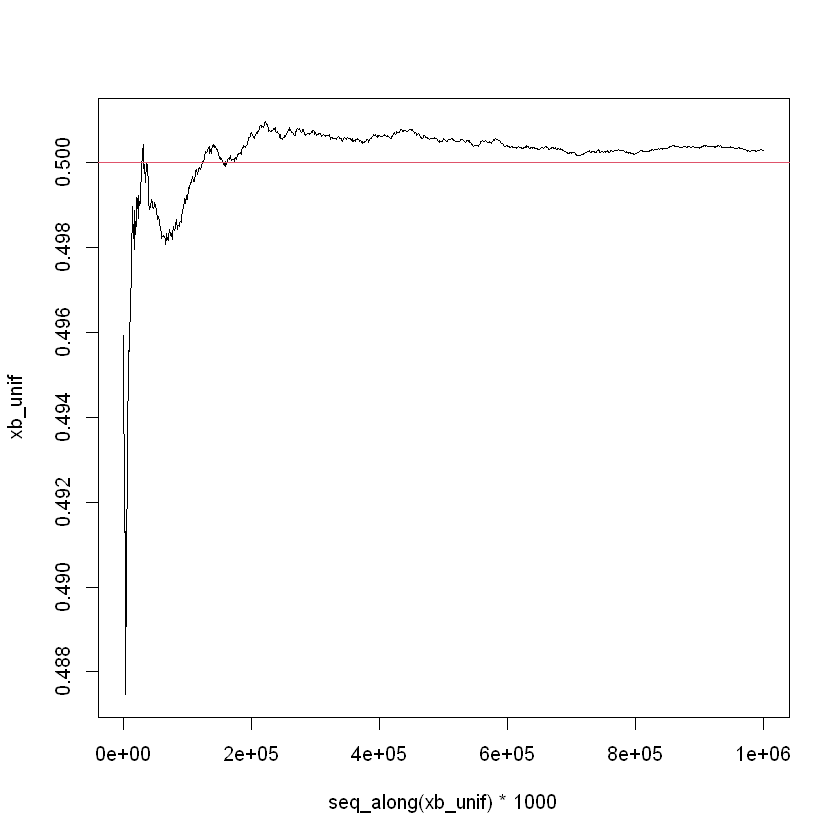

In [15]:
gen_path <- function(rdist, rargs=list(), N=5e5, thin=1000){
  xbar <- numeric(N %/% thin); s <- 0; cnt <- 0; j <- 0
  for(i in 1:N){
    xi <- do.call(rdist, rargs); s <- s + xi; cnt <- cnt + 1
    if(i %% thin == 0){ j <- j + 1; xbar[j] <- s/cnt }
  } ; xbar
}
set.seed(631)
xb_unif <- gen_path("runif", list(1), N=1e6, thin=1000)
plot(seq_along(xb_unif)*1000, xb_unif, type='l'); abline(h=0.5, col=2)

## b)

Pareto($\alpha \approx 2.1$)

For $X = U^{-1/\alpha}$ and $U \sim \mathrm{Uniform}(0,1)$, $X$ is Pareto with scale $1$ and shape $\alpha$

The tail is $P(X > x) = x^{-\alpha}$ for $x \ge 1$

For $\alpha \approx 2.1$, $E[X] = \frac{\alpha}{\alpha - 1} = \frac{2.1}{1.1} \approx 1.909$

$\mathrm{Var}(X) = \frac{\alpha}{(\alpha-1)^2(\alpha-2)} = \frac{2.1}{(1.1)^2(0.1)} \approx 17.4$

SLLN still applies because the mean is finite and $\bar X_n \to 1.909$ almost surely. The variance is finite but about $200$ times the Uniform's, and $E[X^4] = \infty$ because $\alpha < 4$. This is the borderline case, where convergence is guaranteed but the approach is slow and erratic.

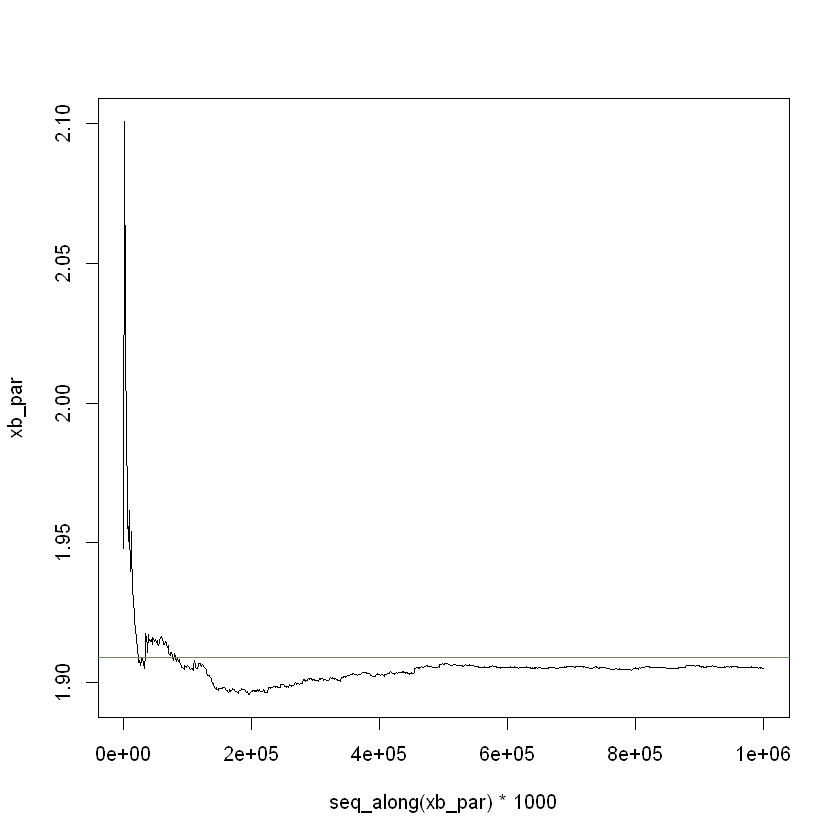

In [16]:
set.seed(631)
rpareto <- function(n, alpha=2.1) (runif(n))^(-1/alpha)
xb_par <- gen_path("rpareto", list(1,2.1), N=1e6, thin=1000)
plot(seq_along(xb_par)*1000, xb_par, type='l'); abline(h=2.1/(2.1-1), col=2)

The path of the uniform distribution is smooth and tight to the average. The observations are bounded so no single sample can move the path much once n is large.

The path of the pareto distribution is not as smooth or tight to the average. The scale of this plot is larger so it doesn't look looser upon immediate inspection but it is.

---
## Problem 7 — Poisson Approximation (14 pts)
Case1: n=400,p=0.01; Case2: n=200, p∈{0.02,0.005}. Compute bounds and empirical TV; compare tails in Case1.

## a)

Let $X = \sum_{i=1}^n X_i$ with independent $X_i \sim \mathrm{Bernoulli}(p_i)$ and $\lambda = \sum_{i=1}^n p_i$

Coupling each $X_i$ with a $\mathrm{Pois}(p_i)$ variable, for every set $A$ of nonnegative integers, $\left|P(X \in A) - \mathrm{Pois}_\lambda(A)\right| \le \sum_{i=1}^n p_i^2$

The total variation distance between the law of $X$ and $\mathrm{Pois}(\lambda)$ is $d_{TV} = \sup_A \left|P(X \in A) - \mathrm{Pois}_\lambda(A)\right|$

$= \frac{1}{2}\sum_{k=0}^{\infty}\left|P(X=k) - \frac{e^{-\lambda}\lambda^k}{k!}\right|$

The bound holds for every $A$, so it holds for $d_{TV} \le \sum_{i=1}^n p_i^2$

+ Case 1: $n = 400$, $p_i = 0.01$

$\lambda = 400(0.01) = 4$

$\sum p_i^2 = 400(0.01)^2 = 0.04$.

+ Case 2: $n = 200$, with alternating values of $0.02$ and $0.005$

$\lambda = 100(0.02) + 100(0.005) = 2.5$

$\sum p_i^2 = 100(0.02)^2 + 100(0.005)^2 = 0.04 + 0.0025 = 0.0425$

## b)

In [17]:
set.seed(631)
n1 <- 400; p1 <- rep(0.01,n1); lam1 <- sum(p1); bound1 <- sum(p1^2)
k <- 0:20; tv1 <- 0.5*sum(abs(dbinom(k,n1,0.01)-dpois(k,lam1)))
n2 <- 200; p2 <- rep(c(0.02,0.005), length.out=n2); lam2 <- sum(p2); bound2 <- sum(p2^2)
reps <- 8e5; set.seed(631)
X2 <- rbinom(reps,1,p2[1]); for(i in 2:n2) X2 <- X2 + rbinom(reps,1,p2[i])
k2 <- 0:20; est_pmf <- sapply(k2, function(kk) mean(X2==kk))
tv2 <- 0.5 * sum(abs(est_pmf - dpois(k2, lam2)))
list(bound1=bound1, tv1=tv1, bound2=bound2, tv2=tv2)

$bound1
[1] 0.04

$tv1
[1] 0.002520331

$bound2
[1] 0.0425

$tv2
[1] 0.004945012

In [18]:
set.seed(631)
pb <- 1
for(p in p2) {
    pb <- c(pb*(1-p), 0) + c(0, pb*p)
}
tv2_exact <- 0.5*sum(abs(pb[1:21] - dpois(0:20, lam2)))
list(tv2_sim=tv2, tv2_exact=tv2_exact, bound2=bound2, bound_over_exact=bound2/tv2_exact)

$tv2_sim
[1] 0.004945012

$tv2_exact
[1] 0.004363652

$bound2
[1] 0.0425

$bound_over_exact
[1] 9.739547

Both bounds are very loose. Case 1 is about 16 times higher and case 2 about 10 times higher than the exact distance

## c)

The tails $P(X \ge k)$ are events so each difference is at most $d_{TV}$

$\max_k \left|P(X \ge k) - P(Y \ge k)\right| \le d_{TV} \le 0.04$ where $Y \sim \mathrm{Pois}(4)$

$\tilde P(Y \ge k) = \frac{1}{2}\left[P(Y \ge k-1) + P(Y \ge k)\right]$ with $P(Y \ge -1) = 1$.

In [19]:
# Tails Case1
k <- 0:20
tail_bin <- rev(cumsum(rev(dbinom(k,400,0.01))))
tail_pois <- rev(cumsum(rev(dpois(k,4))))
max(abs(tail_bin - tail_pois))

[1] 0.001471388

In [20]:
tail_pois_cc <- 0.5*(c(1, tail_pois[-length(tail_pois)]) + tail_pois)
max(abs(tail_bin - tail_pois_cc))

[1] 0.09768505

Without continuity correction, the max absolute deviation is $0.00147$ which is below the exact total variation distance $d_{TV} = 0.00252$ and far below the bound $0.04$.

With continuity correction, the max absolute deviation is $0.0977$ which is much worse.

Continuity correction introduces error because the binomial and the Poisson are both on the same integer lattice so there is no mismatch. For Case 1 the plain Poisson tail is already accurate so continuity correction does not help.

---
## Problem 8 — CLT in Practice (18 pts)
Service times mean 20, sd 4. (a) Normal parent; (b) Lognormal with same mean/sd; (c) one-sided 95% bound for S50 and empirical coverage.

## a)

Let $X_i \sim N(20, 4^2)$ and $S_{25} = \sum_{i=1}^{25} X_i$

$E[S_{25}] = 25(20) = 500$

$\mathrm{SD}(S_{25}) = \sqrt{25}\cdot 4 = 20$

$P(S_{25} \le 450) \approx \Phi\left(\frac{450 - 500}{20}\right) = \Phi(-2.5) \approx 0.0062$

In [21]:
set.seed(631)
mean0 <- 20; sd0 <- 4; set.seed(631); N <- 2e5
muS <- 25*mean0; sdS <- sqrt(25)*sd0; p_clt <- pnorm(450, mean=muS, sd=sdS)
S <- rowSums(matrix(rnorm(N*25, mean=mean0, sd=sd0), nrow=N)); p_emp <- mean(S<=450); ci <- ci95_prop(p_emp,N)
list(p_clt=p_clt, p_emp=p_emp, ci=ci)

$p_clt
[1] 0.006209665

$p_emp
[1] 0.00619

$ci
      lower       upper 
0.005846254 0.006533746

Absolute error is very small because $S_{25}$ is normal

## b)

$p_{\text{CLT}} = \Phi(-2.5) \approx 0.0062$

If $\log X \sim N(m_0, s_0^2)$

$s_0^2 = \log\left(1 + \frac{\sigma^2}{\mu^2}\right) = \log(1.04) \approx 0.0392$

$m_0 = \log\mu - \frac{s_0^2}{2}$

In [24]:
set.seed(631)
s2 <- log(1 + (sd0/mean0)^2); m0 <- log(mean0) - s2/2
SL <- rowSums(matrix(rlnorm(N*25, meanlog=m0, sdlog=sqrt(s2)), nrow=N))
p_clt_ln <- pnorm(450, mean=muS, sd=sdS); p_emp_ln <- mean(SL<=450)
list(p_clt=p_clt_ln, p_emp=p_emp_ln, mc_se=mc_se_mean(SL<=450))

$p_clt
[1] 0.006209665

$p_emp
[1] 0.00444

$mc_se
[1] 0.0001486659

This is the same as the CLT approximation. It only uses the mean and sd, so the two distribution are the same.

The lognormal is right-skewed and it has a lighter lower tail than the normal. Absolute error is about $0.0018$, which is more than $10$ MC standard errors, so it is significant. The CLT is off by about 40%.

## c)

$\mu_{50} = 50(20) = 1000$

$\sigma_{50} = \sqrt{50}\cdot 4 \approx 28.28$

$q = \mu_{50} + z_{0.95}\,\sigma_{50} = 1000 + 1.645(28.28) \approx 1046.5$

$P(S_{50} \le q) \approx 0.95$

In [23]:
set.seed(631)
mu50 <- 50*mean0; sd50 <- sqrt(50)*sd0; qN <- mu50 + qnorm(0.95)*sd50
SN <- rowSums(matrix(rnorm(N*50, mean=mean0, sd=sd0), nrow=N)); covN <- mean(SN<=qN)
SL50 <- rowSums(matrix(rlnorm(N*50, meanlog=m0, sdlog=sqrt(s2)), nrow=N)); qL <- mu50 + qnorm(0.95)*sd50; covL <- mean(SL50<=qL)
list(q_normal=qN, q_lognormal=qL, covN=covN, covL=covL, mc_se_N=mc_se_mean(SN<=qN),mc_se_L=mc_se_mean(SL50<=qL))

$q_normal
[1] 1046.523

$q_lognormal
[1] 1046.523

$covN
[1] 0.949455

$covL
[1] 0.94678

$mc_se_N
[1] 0.0004898492

$mc_se_L
[1] 0.0005019357

The CLT only uses the mean and standard deviation so the thresholds are the same.

For the normal distribution, empirical coverage is 0.9495, versus the target 0.95. The MC SE is about 0.0005, so about 1 SE. This is simulation noise. This makes sense because $S_{50}$ is normal.

For the lognormal distribution, empirical coverage is 0.9468. The MC SE is about 0.0005, that is roughly 6 SEs, so this is not just simulation noise. The lognormal is right-skewed, so $S_{50}$ has a heavier upper tail than the normal, so the CLT bound is slightly off.